In [1]:
import os
import sys
sys.path.insert(0, "../src")

from processor import *
from reusables import *

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from matplotlib.ticker import StrMethodFormatter

pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

In [2]:
DB_PATH = "Desktop/Data Analysis/incident_log.db"
START = '2026-10-12'

In [3]:
df, jobs, issues = prepare("../incident_log.db", start="2026-10-12")
weekly = weekly_summary(df, jobs)
print(len(df), 'incidents loaded')

23 incidents loaded


In [4]:
issues

,severity,check,incident_id,detail
0,ERROR,missing_required,16.0,Lost Item: 'item' is empty
1,ERROR,missing_required,15.0,Lost Item: 'item' is empty
2,ERROR,missing_required,14.0,Lost Item: 'item' is empty
3,ERROR,missing_required,13.0,Lost Item: 'item' is empty
4,ERROR,missing_required,12.0,Lost Item: 'item' is empty
5,ERROR,missing_required,16.0,Lost Item: 'last_location' is empty
6,ERROR,missing_required,15.0,Lost Item: 'last_location' is empty
7,ERROR,missing_required,14.0,Lost Item: 'last_location' is empty
8,ERROR,missing_required,13.0,Lost Item: 'last_location' is empty
9,ERROR,missing_required,12.0,Lost Item: 'last_location' is empty


In [5]:
#Setting variables for baseline and last week dataframes
baseline  = df[df['id'].between(3, 16)]
last_week = df.drop(baseline.index)
all_events = pd.concat([baseline, last_week])
all_jobs = 36 + 36

What is the cost of each loss type and the number of events from this reporting week?

In [6]:
cost_by(last_week)

,events,total
kind,,
Breakage,6,635.4
Lost Item,2,388.8
Repeat Trip,1,113.8


Whats the cost per 100 jobs for the reporting week?

In [7]:
per_100_jobs(last_week, 36)

,events,total,events_per_100,cost_per_100
kind,,,,
Breakage,6,635.4,16.7,1765.00
Lost Item,2,388.8,5.6,1080.00
Repeat Trip,1,113.8,2.8,316.11


Whats the cost per 100 jobs for each waste type across a year at the rate from the week?

In [8]:
annualize(last_week, 36, 52)

,events,total,events_per_100,cost_per_100,annual_events,annual_cost
kind,,,,,,
Breakage,6.0,635.4,16.7,1765.00,312.0,33040.8
Lost Item,2.0,388.8,5.6,1080.00,104.0,20217.6
Repeat Trip,1.0,113.8,2.8,316.11,52.0,5917.6
Total,9.0,1138.0,25.1,3161.11,468.0,59176.0


Whats the baseline look like with the annual projection?

In [9]:
annualize(baseline, 36, 52)

,events,total,events_per_100,cost_per_100,annual_events,annual_cost
kind,,,,,,
Lost Item,5.0,928.8,13.9,2580.00,260.0,48297.6
Breakage,9.0,745.0,25.0,2069.44,468.0,38740.0
Total,14.0,1673.8,38.9,4649.44,728.0,87037.6


What about the total of both baseline and the reporting week?

In [10]:
annualize(all_events, all_jobs, data_weeks=2)

,events,total,events_per_100,cost_per_100,annual_events,annual_cost
kind,,,,,,
Breakage,15.0,1380.4,20.8,1917.22,390.0,35890.4
Lost Item,7.0,1317.6,9.7,1830.00,182.0,34257.6
Repeat Trip,1.0,113.8,1.4,158.06,26.0,2958.8
Total,23.0,2811.8,31.9,3905.28,598.0,73106.8


Whats the bar chart look like for just the reporting week by event type and cost?

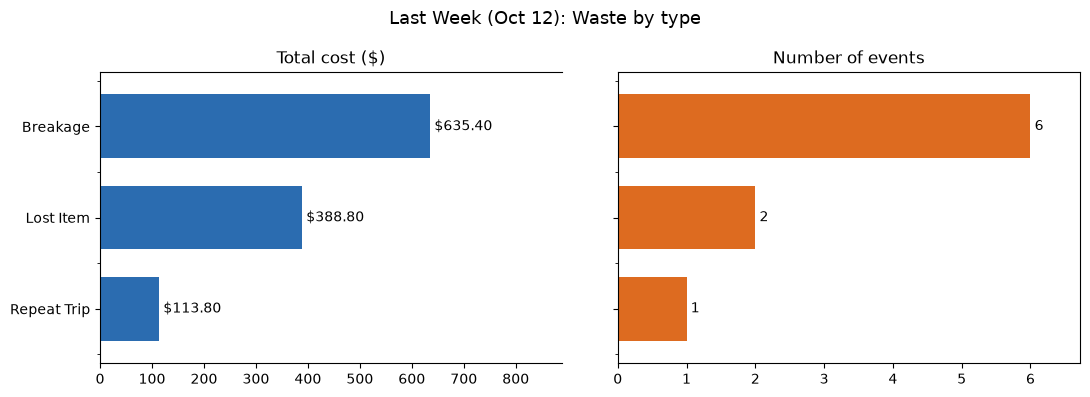

In [11]:
cost_events_chart(cost_by(last_week), 'Last Week (Oct 12): Waste by type')

What about the total of both weeks?

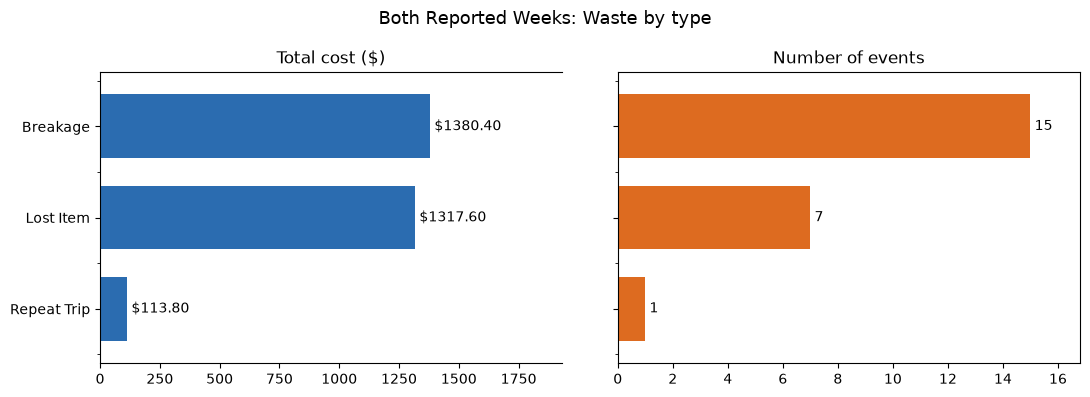

In [12]:
cost_events_chart(cost_by(all_events), 'Both Reported Weeks: Waste by type')

The above graph will be important once there are 3 more weeks of data. I can average across the weeks and then find how the total costs compare to the number of events.

What does the line graph look like of this reporting weeks costs versus the costs of the baseline week?

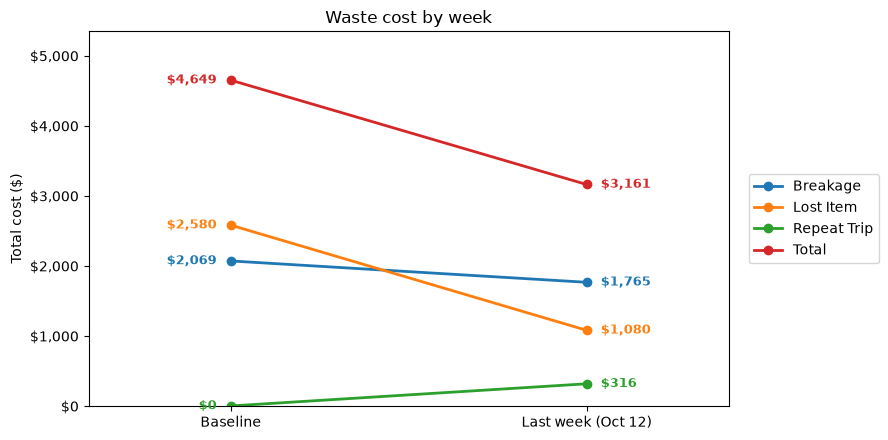

In [13]:
weekly = pd.DataFrame({
    "Baseline": baseline.groupby("kind")["total_cost"].sum() / 36 * 100,
    "Last week (Oct 12)": last_week.groupby("kind")["total_cost"].sum() / 36 * 100,
}).fillna(0).T                       # one row per week, one column per waste type

weekly["Total"] = weekly.sum(axis=1)

ax = weekly.plot(kind="line", marker="o", figsize=(9, 4.5), linewidth=2)
colors = {line.get_label(): line.get_color() for line in ax.lines}

n = len(weekly)
ax.set_xticks(range(n))
ax.set_xticklabels(weekly.index)
ax.set_xlim(-0.4, n - 0.6)
ax.set_ylim(0, weekly.values.max() * 1.15)

# Dollar labels beside each dot, spaced so they never overlap
min_gap = weekly.values.max() * 0.06
for i in range(n):
    last_y = None
    for col, y in weekly.iloc[i].sort_values().items():
        ty = y if last_y is None else max(y, last_y + min_gap)
        last_y = ty
        ax.text(i - 0.04 if i == 0 else i + 0.04, ty, f"${y:,.0f}",
                color=colors[col], ha="right" if i == 0 else "left",
                va="center", fontsize=9, fontweight="bold")

ax.set_title("Waste cost by week")
ax.set_ylabel("Total cost ($)")
ax.set_xlabel("")
ax.yaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))
ax.legend(title="", loc="center left", bbox_to_anchor=(1.02, 0.5))
plt.tight_layout()
plt.show()

Testing the reusable version of the function.

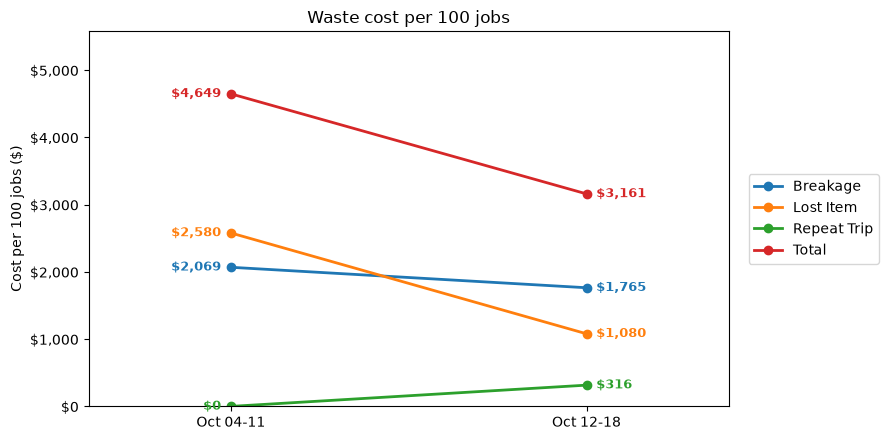

In [14]:
weekly_cost_chart(
    {"Oct 04-11": baseline, "Oct 12-18": last_week},
    jobs={"Oct 04-11": 36, "Oct 12-18": 36}
)

CONCLUSION:

There was significantly less cost in this reporting week compared to the baseline. However, there is still not enough data by 3 weeks. We need the next 3 weeks of data to start making averages and drawing good conclusions on the biggest money wasters. Also, I really need more data from my coworkers. The more data I have, the better conclusions we can draw from my analysis. Overall, there is not enough data yet to make good conclusions but patterns are starting to emerge in what might be the biggest problems to solve.